# Extremizing via likelihoods 

      JMA 3 Sept 2026

Comparing two aggregation methods for combining expert probabilities.  This simulation uses a random sample and compares the mean of the sample with the combination of likelihood ratios ("Bayes Factors") of the sample. 

In [13]:
import numpy as np
from scipy import stats 
import matplotlib.pyplot as plt

DEBUG = 1

### Simulation

To test different belief probability aggregation methods, we generate a distribution of beliefs between 0,1 centered around a mean value using a beta distribution.  The width of the distribution is set by the "sum" parameter, the larger the sum the smaller the width. 

In [78]:
# Code to create a random sample 

def random_beta_probs(no_samples, mean = 1/2, sum = 2, p_limit = 0.01):
    'Probabilities that cluster around a central value. '
    if mean > 1.0 or mean <= 0:
        print("mean must be in the unit interval")
        return None
    a = mean * sum 
    b = sum - a
    if DEBUG: print("a, b: ", a, b)
    samples = []
    for k in range(no_samples):
        # 
        prob = stats.beta.rvs(a, b, loc=0, scale=1) # size = no_samples
        if DEBUG > 1: print(prob)
        if prob > p_limit and prob < 1 - p_limit:
            samples.append(prob)
    print(len(samples), ' samples generated')
    return samples
   
def llhood_from_p(p):
    return p / (1 - p )

### Compute the comparative probability mean versus beliefs

In [95]:
# Set size, mean and variability of the sample

probs = random_beta_probs(14, 0.48, 2)
p_mean = np.mean(probs)
p_std = np.array(probs).std()
print('Probability sample mean & std: ', p_mean, p_std)

# Convert probs into log likelihoods
log_likelihoods = [np.log(llhood_from_p(p)) for p in probs]

# Belief update - of log likelihoods 
ll_sum = sum(log_likelihoods) # /len(log_likelihoods)
updated_belief = np.exp(ll_sum)/(np.exp(ll_sum) +1)
# if DEBUG: 
print( 'p_mean, v/s updated belief: ', p_mean, updated_belief )

# print('sum log likelihood , Aggregate p: ', ll_sum, ll_sum/(ll_sum+1) )

a, b:  0.96 1.04
14  samples generated
Probability sample mean & std:  0.5260815441641541 0.2723773296659977
p_mean, v/s updated belief:  0.5260815441641541 0.8144308391720975


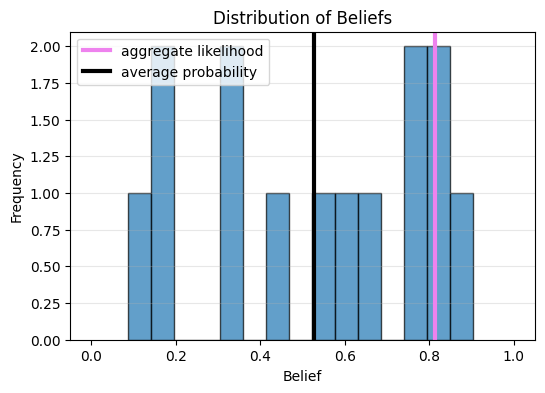

In [96]:
plt.figure(figsize=(6, 4))
plt.hist(probs, bins=15, edgecolor='black', alpha=0.7)
plt.axvline(updated_belief, color= 'violet', linewidth=3, label='aggregate likelihood')
plt.axvline(p_mean, color='black', linewidth=3, label='average probability')
plt.xlabel('Belief')
plt.ylabel('Frequency')
plt.xlim(-0.05,1.05)
plt.title('Distribution of Beliefs')
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.show()